## Modèles classiques : Random Forest, SVM et XGBoost (expérience E8)

#### Objectif

Comparer l'ANN retenu à des modèles classiques, réglés avec le même soin, pour savoir si l'ANN fait mieux sur ces données.

#### Principe directeur

Pour une comparaison équitable, seul le modèle change : mêmes données, mêmes partitions, mêmes variables (F3), mêmes graines, mêmes critères, sans correction du déséquilibre. Chaque modèle est réglé sur la validation.

### Partie commune

#### Importations

In [1]:
import os
import json
import time
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix)
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier

#### Mêmes données et mêmes partitions que l'ANN

Nous utiliserons  `config_ann.json` pour garder les memes decoupages que ANN afin de faire une comparaisons equitable. Le découpage est refait avec la même graine, puis comparé au fichier `partitions.csv` de l'expérience A.

In [2]:
data = pd.read_csv("donnees_propres.csv", sep=",")

# Configuration finale de l'ANN : on reprend ses variables et ses graines pour une comparaison équitable
with open(os.path.join("resultats", "modeles_finaux", "config_ann.json"), encoding="utf-8") as f:
    CONFIG_ANN = json.load(f)
VARIABLES = CONFIG_ANN["variables"]             # F3 : 10 bandes + 9 indices
GRAINES = CONFIG_ANN["graines"]                 # [0, 1, 2, 3, 4]
SEED_PARTITION = CONFIG_ANN["seed_partition"]   # 42

BANDES = [f"B{i}" for i in range(1, 11)]
encodeur = LabelEncoder()
y = encodeur.fit_transform(data["class_name"])
NOMS_CLASSES = list(encodeur.classes_)
N_CLASSES = len(NOMS_CLASSES)

# Même découpage 70 / 15 / 15 que dans l'expérience A, vérifié avec le fichier sauvegardé
idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED_PARTITION)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEED_PARTITION)
partitions_A = pd.read_csv(os.path.join("resultats", "experience_A", "partitions.csv"))
ensemble = np.empty(len(y), dtype=object)
ensemble[idx_train], ensemble[idx_val], ensemble[idx_test] = "train", "validation", "test"
assert (partitions_A["ensemble"].to_numpy() == ensemble).all(), "Partitions différentes de l'expérience A !"

# Même standardisation (apprise sur l'entraînement) pour tous les modèles 
X = data[VARIABLES].to_numpy(dtype="float32")
normaliseur = StandardScaler().fit(X[idx_train])
X_train, y_train = normaliseur.transform(X[idx_train]), y[idx_train]
X_val, y_val = normaliseur.transform(X[idx_val]), y[idx_val]

DOSSIER_FINAL = os.path.join("resultats", "modeles_finaux")
COULEURS_CLASSES = {nom: plt.get_cmap("tab10")(i) for i, nom in enumerate(sorted(NOMS_CLASSES))}
noms_courts = [n.split(" ")[0] for n in NOMS_CLASSES]
print(f"{len(VARIABLES)} variables | entraînement : {len(idx_train)} | validation : {len(idx_val)} | test (non utilisé) : {len(idx_test)}")

19 variables | entraînement : 700 | validation : 150 | test (non utilisé) : 150


#### Fonctions communes

Mêmes métriques que pour l'ANN, une fonction d'évaluation sur la validation, et le graphique des bandes de chevauchement.

In [3]:
def calculer_metriques(y_vrai, y_pred):
    """Mêmes métriques que pour l'ANN."""
    return {
        "accuracy": accuracy_score(y_vrai, y_pred),
        "precision_macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_pondere": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_vrai, y_pred),
    }


def evaluer(fabrique, graine, nom):
    """Entraîne un modèle (fabrique(graine) le crée) sur l'entraînement et l'évalue sur la validation."""
    modele = fabrique(graine)
    debut = time.perf_counter()
    modele.fit(X_train, y_train)
    duree = time.perf_counter() - debut
    pred_train, pred_val = modele.predict(X_train), modele.predict(X_val)
    m_train, m_val = calculer_metriques(y_train, pred_train), calculer_metriques(y_val, pred_val)
    ligne = {"config": nom, "graine": graine, "temps_s": duree,
             **{f"val_{k}": v for k, v in m_val.items()},
             "train_f1_macro": m_train["f1_macro"],
             "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"]}
    f1_classes = f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)
    return ligne, f1_classes, pred_val


def bandes_chevauchement(df, configs, reference, titre, fichier, etiquette_ref):
    """Bandes moyenne ± écart-type sur les 5 critères, comparées à la référence (même code que pour l'ANN)."""
    criteres = [("val_f1_macro", "Macro-F1 val"), ("val_recall_macro", "Rappel macro val"),
                ("val_precision_macro", "Précision macro val"), ("val_accuracy", "Accuracy val\n(complément)"),
                ("ecart_f1_train_val", "Écart\nF1 train - val")]
    stats = df.groupby("config")[[c for c, _ in criteres]].agg(["mean", "std"]).loc[configs]
    fig, axes = plt.subplots(1, len(criteres), figsize=(24, 1.6 + 1.1 * len(configs)), sharey=True)
    y_pos = np.arange(len(configs))[::-1]
    for ax, (col, t) in zip(axes, criteres):
        m, s = stats[(col, "mean")], stats[(col, "std")].fillna(0)
        bas_ref, haut_ref = m[reference] - s[reference], m[reference] + s[reference]
        ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")
        for yi, cfg in zip(y_pos, configs):
            bas, haut = m[cfg] - s[cfg], m[cfg] + s[cfg]
            c = "#8a96a3" if cfg == reference else ("#2e5c8b" if bas <= haut_ref and haut >= bas_ref else "#c0392b")
            ax.plot([bas, haut], [yi, yi], color=c, lw=6, solid_capstyle="round")
            ax.plot(m[cfg], yi, "o", color="white", mec=c, mew=2.5, ms=10)
            ax.text(haut, yi, f"  {m[cfg]:.3f}", va="center", fontsize=11, color=c)
        ax.set_title(t, fontsize=13)
        ax.margins(x=0.35, y=0.3)
        ax.grid(axis="x", alpha=0.3)
    axes[0].set_yticks(y_pos, configs)
    axes[0].tick_params(axis="y", labelsize=12)
    legende = [Line2D([0], [0], color="#8a96a3", lw=6, label=etiquette_ref),
               Line2D([0], [0], color="#2e5c8b", lw=6, label="chevauchement : différence non nette"),
               Line2D([0], [0], color="#c0392b", lw=6, label="écart net")]
    fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.97), frameon=False, fontsize=12)
    fig.suptitle(titre, fontsize=15, y=1.06)
    plt.tight_layout(rect=[0, 0, 1, 0.88])
    plt.savefig(fichier, dpi=200, bbox_inches="tight")
    plt.show()

#### Référence ANN et blocs de la validation spatiale

On relit les résultats de l'ANN retenu (expérience F) et on reconstruit exactement les mêmes plis aléatoires et spatiaux.

In [4]:
# Résultats de l'ANN retenu (F3, 5 graines), enregistrés pendant l'expérience F
REF_ANN = "ANN (référence)"
ann = pd.read_csv(os.path.join("resultats", "experience_F", "resultats_detailles.csv"))
ann = ann.loc[ann["config"] == "F3 Bandes + indices"].assign(config=REF_ANN)
ann_vc = pd.read_csv(os.path.join("resultats", "experience_F", "validation_aleatoire_spatiale.csv"))
ann_vc = ann_vc.loc[ann_vc["config"] == "F3 Bandes + indices"].assign(config=REF_ANN)

# Mêmes blocs et mêmes plis que pour l'ANN (entraînement + validation ; le test n'est pas touché)
idx_dev = np.concatenate([idx_train, idx_val])
y_dev = np.concatenate([y_train, y_val])
coords_dev = data.loc[idx_dev, ["x", "y"]].to_numpy()
blocs_dev = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(coords_dev)
PLIS = {"aléatoire": list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(idx_dev, y_dev)),
        "spatiale": list(GroupKFold(n_splits=5).split(idx_dev, y_dev, groups=blocs_dev))}


def validation_croisee(fabrique, nom, graine=0):
    """Validation croisée aléatoire et spatiale (5 plis chacune), avec la standardisation apprise dans chaque pli."""
    X_dev = data.loc[idx_dev, VARIABLES].to_numpy(dtype="float32")
    lignes = []
    for schema, plis in PLIS.items():
        for p, (i_app, i_test) in enumerate(plis):
            norm = StandardScaler().fit(X_dev[i_app])
            modele = fabrique(graine).fit(norm.transform(X_dev[i_app]), y_dev[i_app])
            pred = modele.predict(norm.transform(X_dev[i_test]))
            vrai = y_dev[i_test]
            lignes.append({"config": nom, "validation": schema, "pli": p,
                           "f1_macro": f1_score(vrai, pred, average="macro", zero_division=0),
                           "rappel_macro": recall_score(vrai, pred, average="macro", zero_division=0),
                           "accuracy": accuracy_score(vrai, pred)})
    return pd.DataFrame(lignes)

print(f"ANN de référence : Macro-F1 val = {ann['val_f1_macro'].mean():.3f} ± {ann['val_f1_macro'].std():.3f}")

ANN de référence : Macro-F1 val = 0.389 ± 0.041


### Random Forest

#### Recherche des hyperparamètres sur la validation

Grille de 18 combinaisons (`max_features`, `min_samples_leaf`, `max_depth`), 500 arbres, 5 graines chacune. La combinaison retenue est celle du meilleur Macro-F1 moyen en validation.

In [6]:
DOSSIER_RF = os.path.join("resultats", "modeles_classiques", "random_forest")
os.makedirs(DOSSIER_RF, exist_ok=True)

GRILLE_RF = {
    "n_estimators": [530],
    "max_features": ["sqrt", 0.5],
    "min_samples_leaf": [1, 3, 5],
    "max_depth": [None, 10, 20],
}
combinaisons = [dict(zip(GRILLE_RF, v)) for v in product(*GRILLE_RF.values())]
print(f"{len(combinaisons)} combinaisons x {len(GRAINES)} graines = {len(combinaisons) * len(GRAINES)} entraînements")


def fabrique_rf(params):
    """Renvoie une fonction qui crée une forêt avec ces hyperparamètres et une graine donnée."""
    return lambda graine: RandomForestClassifier(**params, random_state=graine, n_jobs=-1)


grille_rf, PARAMS_GRILLE = [], {}
for params in combinaisons:
    nom = f"mf={params['max_features']} | leaf={params['min_samples_leaf']} | depth={params['max_depth']}"
    PARAMS_GRILLE[nom] = params
    for graine in GRAINES:
        ligne, _, _ = evaluer(fabrique_rf(params), graine, nom)
        grille_rf.append(ligne)
grille_rf = pd.DataFrame(grille_rf)
grille_rf.to_csv(os.path.join(DOSSIER_RF, "grille_resultats.csv"), index=False)

# Classement des combinaisons selon le Macro-F1 moyen en validation (critère principal)
recap_grille = (grille_rf.groupby("config")
                .agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                     rappel=("val_recall_macro", "mean"), ecart=("ecart_f1_train_val", "mean"))
                .sort_values("f1", ascending=False))
display(recap_grille.round(3))

MEILLEUR_RF = recap_grille.index[0]
PARAMS_RF = PARAMS_GRILLE[MEILLEUR_RF]
print("Combinaison retenue :", MEILLEUR_RF, "->", PARAMS_RF)

18 combinaisons x 5 graines = 90 entraînements


,f1,f1_sd,rappel,ecart
config,,,,
mf=sqrt | leaf=1 | depth=20,0.386,0.035,0.374,0.614
mf=sqrt | leaf=1 | depth=None,0.384,0.038,0.372,0.616
mf=sqrt | leaf=1 | depth=10,0.378,0.043,0.365,0.449
mf=0.5 | leaf=1 | depth=20,0.376,0.017,0.375,0.624
mf=0.5 | leaf=1 | depth=None,0.375,0.018,0.374,0.625
mf=0.5 | leaf=3 | depth=None,0.359,0.007,0.360,0.353
mf=0.5 | leaf=3 | depth=20,0.359,0.007,0.360,0.353
mf=sqrt | leaf=3 | depth=None,0.359,0.006,0.358,0.327
mf=0.5 | leaf=5 | depth=20,0.359,0.006,0.359,0.248


Combinaison retenue : mf=sqrt | leaf=1 | depth=20 -> {'n_estimators': 530, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'max_depth': 20}


#### Visualisation de la recherche

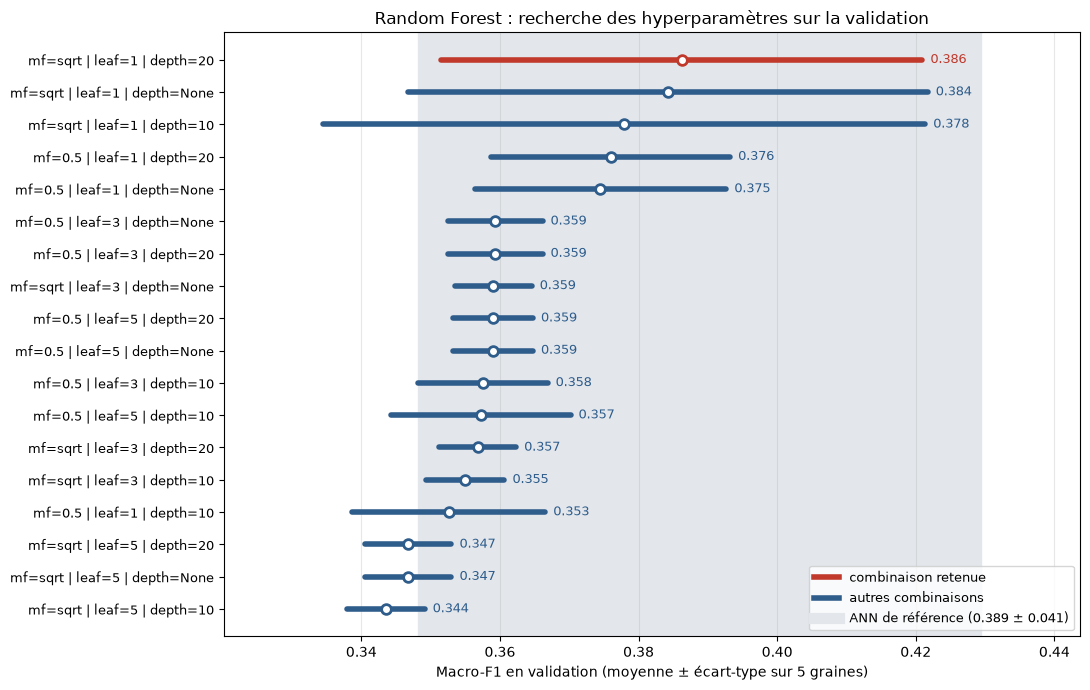

In [11]:
fig, ax = plt.subplots(figsize=(11, 7))
ordre = recap_grille.index[::-1]
for yi, cfg in enumerate(ordre):
    m, s = recap_grille.loc[cfg, "f1"], recap_grille.loc[cfg, "f1_sd"]
    c = "#c0392b" if cfg == MEILLEUR_RF else "#2e5c8b"
    ax.plot([m - s, m + s], [yi, yi], color=c, lw=4, solid_capstyle="round")
    ax.plot(m, yi, "o", color="white", mec=c, mew=2, ms=7)
    ax.text(m + s, yi, f"  {m:.3f}", va="center", fontsize=9, color=c)
m_ann, s_ann = ann["val_f1_macro"].mean(), ann["val_f1_macro"].std()
ax.axvspan(m_ann - s_ann, m_ann + s_ann, color="#e3e7ec", zorder=0)
ax.set_yticks(range(len(ordre)), ordre, fontsize=9)
ax.set_xlabel("Macro-F1 en validation (moyenne ± écart-type sur 5 graines)")
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#c0392b", lw=4, label="combinaison retenue"),
                   Line2D([0], [0], color="#2e5c8b", lw=4, label="autres combinaisons"),
                   Line2D([0], [0], color="#e3e7ec", lw=8, label=f"ANN de référence ({m_ann:.3f} ± {s_ann:.3f})")],
          loc="lower right", fontsize=9)
ax.set_title("Random Forest : recherche des hyperparamètres sur la validation")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RF, "recherche_hyperparametres.png"), dpi=150)
plt.show()

#### Random Forest retenu : 5 graines et tableau récapitulatif

Une forêt prédit presque parfaitement ses propres données d'entraînement (F1 train proche de 1) : l'écart train − val n'a donc pas le même sens que pour l'ANN. Le score hors sac (OOB), calculé sur les observations qu'aucun arbre concerné n'a vues, donne une estimation honnête sur l'entraînement.

In [7]:
NOM_RF = "Random Forest"
resultats_rf, f1_classes_rf, predictions_rf = [], {}, {}
for graine in GRAINES:
    ligne, f1c, pred = evaluer(lambda g: RandomForestClassifier(**PARAMS_RF, random_state=g, n_jobs=-1), graine, NOM_RF)
    resultats_rf.append(ligne)
    f1_classes_rf[graine], predictions_rf[graine] = f1c, pred
resultats_rf = pd.DataFrame(resultats_rf)

# Score « hors sac » (OOB) : chaque observation d'entraînement est prédite par les arbres qui ne l'ont pas vue.
# Une forêt prédit presque parfaitement son propre entraînement (F1 train proche de 1), donc l'écart train - val
# n'a pas le même sens que pour l'ANN ; le F1 OOB donne une estimation honnête sur l'entraînement.
f1_oob = []
for graine in GRAINES:
    foret = RandomForestClassifier(**PARAMS_RF, random_state=graine, n_jobs=-1, oob_score=True).fit(X_train, y_train)
    f1_oob.append(f1_score(y_train, foret.oob_decision_function_.argmax(axis=1), average="macro", zero_division=0))
resultats_rf["oob_f1_macro"] = f1_oob
resultats_rf.to_csv(os.path.join(DOSSIER_RF, "resultats_detailles.csv"), index=False)
print(f"F1 train = {resultats_rf['train_f1_macro'].mean():.3f} | F1 OOB = {np.mean(f1_oob):.3f} ± {np.std(f1_oob, ddof=1):.3f} | "
      f"F1 val = {resultats_rf['val_f1_macro'].mean():.3f}")

comparaison_rf = pd.concat([ann, resultats_rf], ignore_index=True)
cols = ["val_f1_macro", "val_recall_macro", "val_precision_macro", "val_mcc", "val_accuracy", "ecart_f1_train_val", "temps_s"]
recap_rf = comparaison_rf.groupby("config")[cols].agg(["mean", "std"]).loc[[REF_ANN, NOM_RF]]
tableau_rf = pd.DataFrame(index=recap_rf.index)
for c in cols:
    dec = 1 if c == "temps_s" else 3
    tableau_rf[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_rf[(c, "mean")], recap_rf[(c, "std")])]
tableau_rf.to_csv(os.path.join(DOSSIER_RF, "recapitulatif.csv"))
display(tableau_rf)

F1 train = 1.000 | F1 OOB = 0.365 ± 0.005 | F1 val = 0.386


,val_f1_macro,val_recall_macro,val_precision_macro,val_mcc,val_accuracy,ecart_f1_train_val,temps_s
config,,,,,,,
ANN (référence),0.389 ± 0.041,0.377 ± 0.023,0.469 ± 0.097,0.330 ± 0.025,0.645 ± 0.011,0.054 ± 0.034,35.2 ± 3.4
Random Forest,0.386 ± 0.035,0.374 ± 0.020,0.442 ± 0.081,0.301 ± 0.029,0.623 ± 0.014,0.614 ± 0.035,2.6 ± 0.1


#### Bandes de chevauchement : Random Forest contre l'ANN de référence

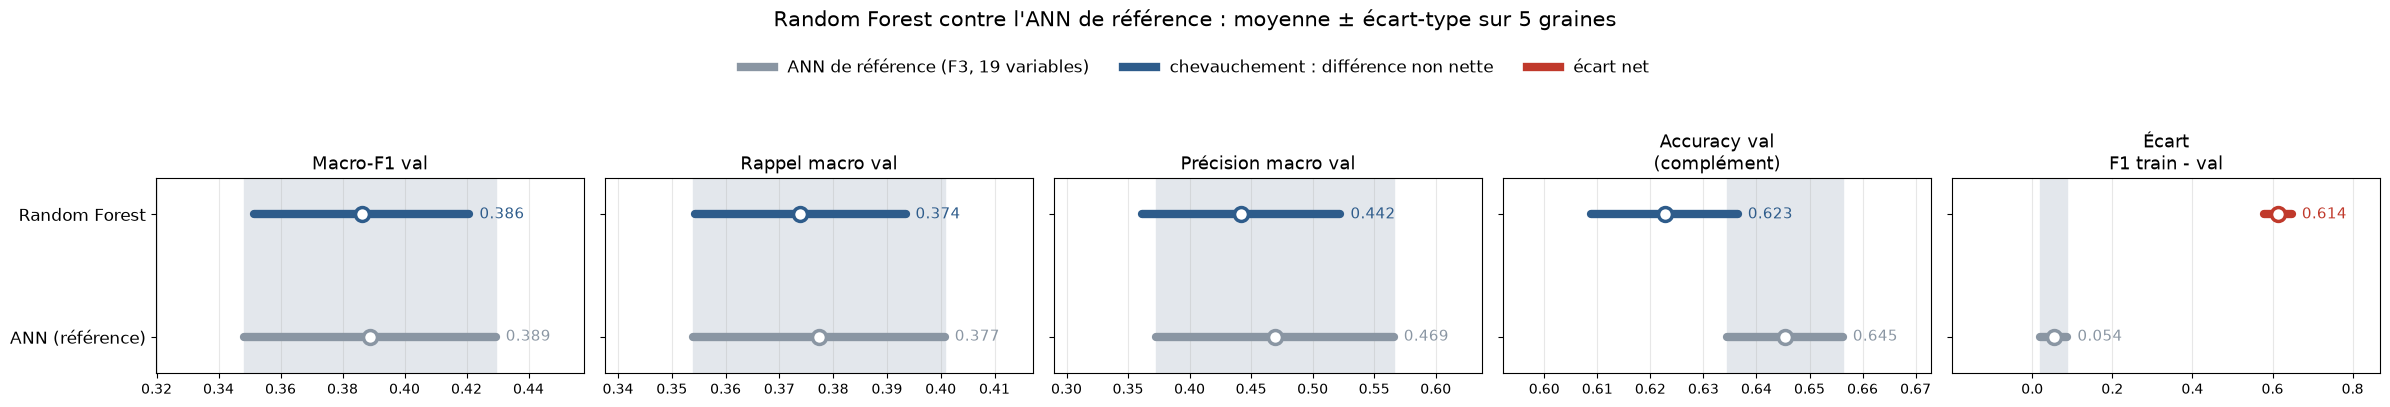

In [8]:
bandes_chevauchement(comparaison_rf, [NOM_RF, REF_ANN], REF_ANN,
                     "Random Forest contre l'ANN de référence : moyenne ± écart-type sur 5 graines",
                     os.path.join(DOSSIER_RF, "chevauchement_ann.png"), "ANN de référence (F3, 19 variables)")

#### F1 par classe et matrice de confusion

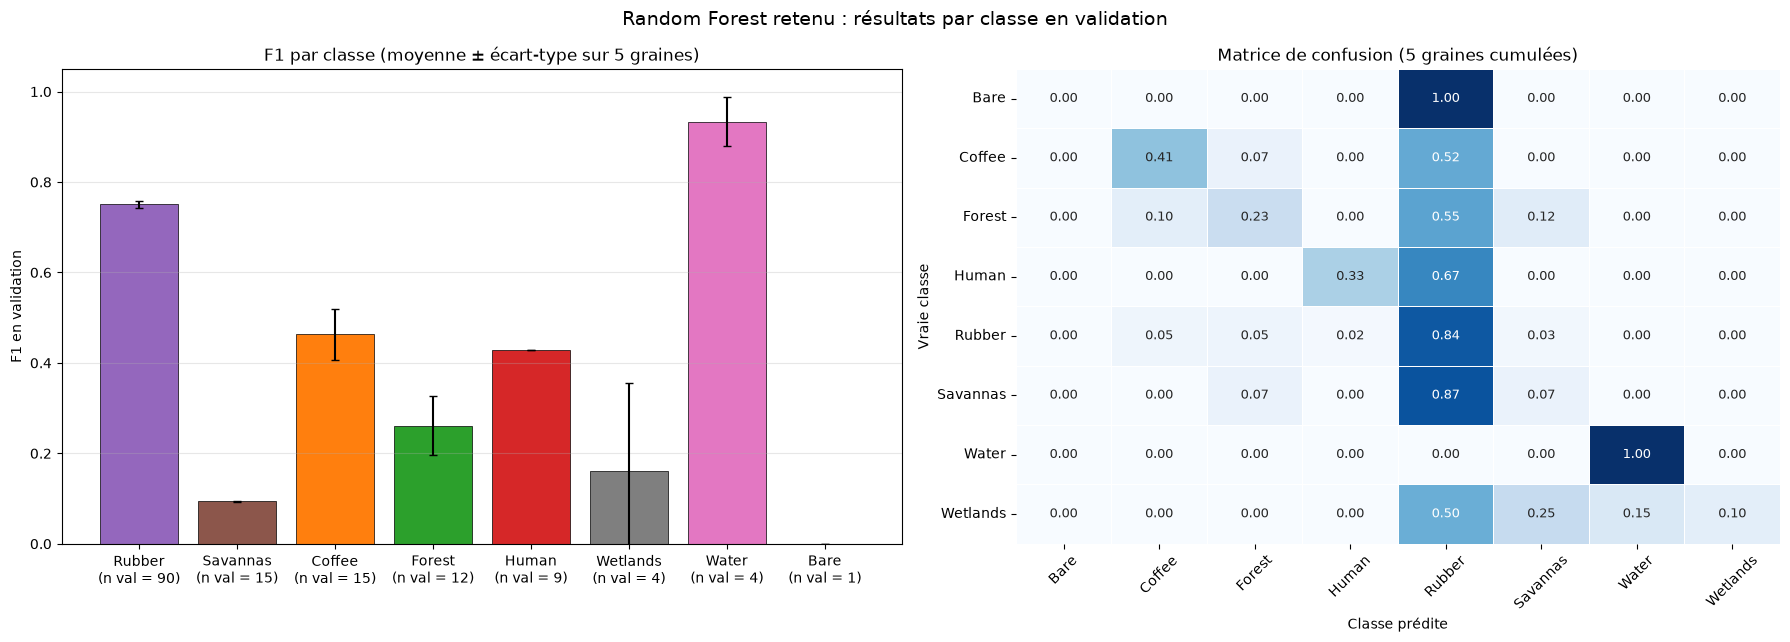

In [9]:
ordre_classes = np.argsort(np.bincount(y_train))[::-1]          # de la plus fréquente à la plus rare
f1s = np.array([f1_classes_rf[g] for g in GRAINES])[:, ordre_classes]

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].bar(range(N_CLASSES), f1s.mean(axis=0), yerr=f1s.std(axis=0), capsize=3,
            color=[COULEURS_CLASSES[NOMS_CLASSES[k]] for k in ordre_classes], edgecolor="black", lw=0.5)
axes[0].set_xticks(range(N_CLASSES), [f"{noms_courts[k]}\n(n val = {np.sum(y_val == k)})" for k in ordre_classes])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("F1 en validation")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("F1 par classe (moyenne ± écart-type sur 5 graines)")

cm = sum(confusion_matrix(y_val, predictions_rf[g], labels=range(N_CLASSES)) for g in GRAINES)
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=noms_courts, yticklabels=noms_courts, annot_kws={"fontsize": 9},
            linewidths=0.5, linecolor="white", ax=axes[1])
axes[1].set_xlabel("Classe prédite")
axes[1].set_ylabel("Vraie classe")
axes[1].tick_params(axis="x", rotation=45)
axes[1].tick_params(axis="y", rotation=0)
axes[1].set_title("Matrice de confusion (5 graines cumulées)")
fig.suptitle("Random Forest retenu : résultats par classe en validation", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RF, "f1_classes_confusion.png"), dpi=150)
plt.show()

#### Double validation : aléatoire et spatiale

Mêmes plis que pour l'ANN (5 plis aléatoires, 5 blocs géographiques), sur entraînement + validation.

f1_macro   rappel_macro       accuracy
config          validation                                             
ANN (référence) aléatoire   0.361 ± 0.033  0.350 ± 0.026  0.641 ± 0.011
                spatiale    0.288 ± 0.070  0.291 ± 0.074  0.636 ± 0.103
Random Forest   aléatoire   0.373 ± 0.071  0.353 ± 0.058  0.633 ± 0.043
                spatiale    0.251 ± 0.085  0.252 ± 0.073  0.617 ± 0.106

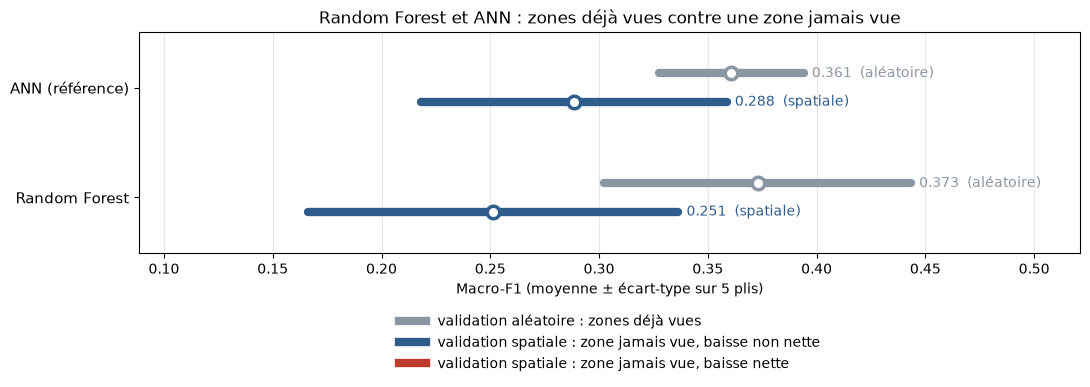

In [10]:
vc_rf = validation_croisee(lambda g: RandomForestClassifier(**PARAMS_RF, random_state=g, n_jobs=-1), NOM_RF)
vc_rf.to_csv(os.path.join(DOSSIER_RF, "validation_aleatoire_spatiale.csv"), index=False)
vc = pd.concat([ann_vc, vc_rf], ignore_index=True)
recap_vc = vc.groupby(["config", "validation"])[["f1_macro", "rappel_macro", "accuracy"]].agg(["mean", "std"])
tableau_vc = pd.DataFrame(index=recap_vc.index)
for c in ["f1_macro", "rappel_macro", "accuracy"]:
    tableau_vc[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(recap_vc[(c, "mean")], recap_vc[(c, "std")])]
display(tableau_vc)

fig, ax = plt.subplots(figsize=(11, 4.2))
for yi, config in enumerate([NOM_RF, REF_ANN]):
    m_a, s_a = recap_vc.loc[(config, "aléatoire"), ("f1_macro", "mean")], recap_vc.loc[(config, "aléatoire"), ("f1_macro", "std")]
    m_s, s_s = recap_vc.loc[(config, "spatiale"), ("f1_macro", "mean")], recap_vc.loc[(config, "spatiale"), ("f1_macro", "std")]
    c_s = "#c0392b" if (m_s + s_s < m_a - s_a) else "#2e5c8b"
    for m, s, c, dy, nom in [(m_a, s_a, "#8a96a3", 0.13, "aléatoire"), (m_s, s_s, c_s, -0.13, "spatiale")]:
        ax.plot([m - s, m + s], [yi + dy, yi + dy], color=c, lw=6, solid_capstyle="round")
        ax.plot(m, yi + dy, "o", color="white", mec=c, mew=2.5, ms=9)
        ax.text(m + s, yi + dy, f"  {m:.3f}  ({nom})", va="center", fontsize=10, color=c)
ax.set_yticks([0, 1], [NOM_RF, REF_ANN], fontsize=11)
ax.set_xlabel("Macro-F1 (moyenne ± écart-type sur 5 plis)")
ax.margins(x=0.28, y=0.3)
ax.grid(axis="x", alpha=0.3)
ax.legend(handles=[Line2D([0], [0], color="#8a96a3", lw=6, label="validation aléatoire : zones déjà vues"),
                   Line2D([0], [0], color="#2e5c8b", lw=6, label="validation spatiale : zone jamais vue, baisse non nette"),
                   Line2D([0], [0], color="#c0392b", lw=6, label="validation spatiale : zone jamais vue, baisse nette")],
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1, frameon=False, fontsize=10)
ax.set_title("Random Forest et ANN : zones déjà vues contre une zone jamais vue")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RF, "validation_aleatoire_spatiale.png"), dpi=150)
plt.show()

#### Configuration finale du Random Forest

Hyperparamètres retenus et scores des deux validations, enregistrés dans `resultats/modeles_finaux/config_rf.json`. Le modèle est figé ; le jeu de test n'a pas encore été utilisé.

In [ ]:
CONFIG_RF_FINAL = {
    "modele": "Random Forest",
    "hyperparametres": PARAMS_RF,
    "choix": "meilleur Macro-F1 moyen en validation (5 graines) parmi la grille",
    "grille": {k: [str(x) for x in v] for k, v in GRILLE_RF.items()},
    "variables": VARIABLES,
    "n_variables": len(VARIABLES),
    "desequilibre": "sans correction (comme l'ANN)",
    "standardisation": "StandardScaler appris sur l'entraînement (sans effet sur les arbres, gardé pour un pipeline commun)",
    "graines": GRAINES,
    "seed_partition": SEED_PARTITION,
    "validation_croisee_dev": {
        schema: {"f1_macro_moyenne": round(float(recap_vc.loc[(NOM_RF, schema), ("f1_macro", "mean")]), 3),
                 "f1_macro_ecart_type": round(float(recap_vc.loc[(NOM_RF, schema), ("f1_macro", "std")]), 3)}
        for schema in PLIS},
}
os.makedirs(DOSSIER_FINAL, exist_ok=True)
with open(os.path.join(DOSSIER_FINAL, "config_rf.json"), "w", encoding="utf-8") as f:
    json.dump(CONFIG_RF_FINAL, f, ensure_ascii=False, indent=2)
print(json.dumps({k: v for k, v in CONFIG_RF_FINAL.items() if k != "variables"}, ensure_ascii=False, indent=2))